# 11월 25일 TIL
---

## 01 수업 내용 복기(코드위주)
===

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 선형회귀 모델 임포트 
from sklearn.linear_model import LinearRegression

# 한글폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"

# 데이터 (딕셔너리)
data = {
    "hours": [1, 2, 3, 4, 5],
    "scores": [47, 53, 65, 73, 87]
}

# 판다스 데이터프레임으로 전환
df = pd.DataFrame(data)
df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


In [2]:
# 입력 데이터 (피쳐):2차원 - 독립변수
X = df[["hours"]] # 공부시간
# 출력 데이터 (타겟):1차원 - 종속변수
y = df["scores"] # 시험점수

In [3]:
# 선형회귀 모델 객체 생성
model = LinearRegression()
# 모델학습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [4]:
# 다중 선형회귀의 경우 결과값이 배열로 리턴
# 기울기는 배열 리턴 
print(f"기울기: {model.coef_[0]:.2f}") # 기울기 Weight
print(f"절편: {model.intercept_:.2f}") # 절편 Bias

기울기: 10.00
절편: 35.00


In [5]:
# 6시간 학습한 학생의 성적 예측
new_data = pd.DataFrame({"hours": [6]}) # X 독립변수 1개 추가
predicted_score = model.predict(new_data)
print(f"6시간 학습한 학생의 예상 성적: {predicted_score[0]:.2f}")

6시간 학습한 학생의 예상 성적: 95.00


학습 데이터에 대한 예측값: [45. 55. 65. 75. 85.]


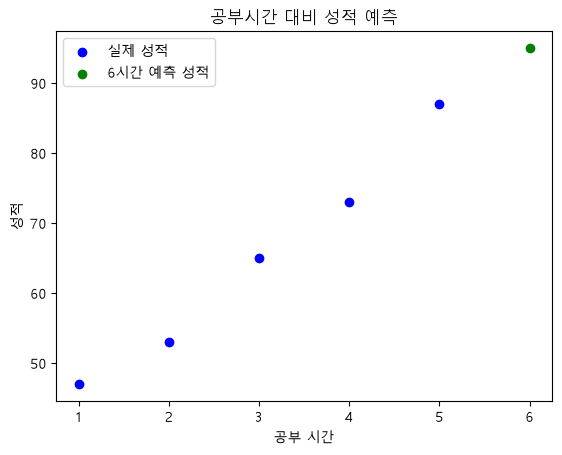

In [6]:
# 학습 데이터에 대한 예측값
y_pred = model.predict(X)
print("학습 데이터에 대한 예측값:", y_pred)

# figure 캔버스 생성, 사이즈 정해주기 
plt.Figure(figsize=(6, 3))

# 실제 생성(산점도)
plt.scatter(X["hours"], y, color="blue", label="실제 성적")

# 6시간 학습한 학생의 예측 성적
plt.scatter(6, predicted_score[0], color="green", label="6시간 예측 성적")

plt.title("공부시간 대비 성적 예측")
plt.xlabel("공부 시간")
plt.ylabel("성적")
plt.legend()
plt.show()

In [7]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 오차의 크기를 직관적으로 이해 
mae = mean_absolute_error(y, y_pred)
print(f"학습데이터에 대한 평균 절대 오차(MAE): {mae:.2f}")

# 제곱하는 이유는 큰 오차에 대해서 민감하게 반응
mse = mean_squared_error(y, y_pred)
print(f"학습데이터에 대한 평균 제곱 오차(MSE): {mse:.2f}")

# 모델이 실제 데이터를 얼마만큼 정확한지를 나타내는 지표
# 0<==>1
# 음수일경우 학습 실패 
r2 = r2_score(y, y_pred)
print(f"학습데이터에 대한 결정 계수(R^2): {r2:.2f}")

학습데이터에 대한 평균 절대 오차(MAE): 1.60
학습데이터에 대한 평균 제곱 오차(MSE): 3.20
학습데이터에 대한 결정 계수(R^2): 0.98


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 학습 데이터 생성 
df = pd.DataFrame({
    "hours": [1, 2, 3, 4, 5],
    "scores": [47, 53, 65, 73, 87]
})

# 독립변수 (입력변수: Feature)
X = df[["hours"]]
# 종속변수 (정답: Target)
y = df["scores"]

In [9]:
# 선형회귀 
model = LinearRegression()
# 모델학습
model.fit(X, y)
# 예측값
y_pred = model.predict(X)
# 결과값: 경사하강법으로 도달하려는 목표 
print(f"weight: {model.coef_[0]:.2f}")
print(f"Bias: {model.intercept_:.2f}")
print(f"MSE: {mean_squared_error(y, y_pred):.4f}")


weight: 10.00
Bias: 35.00
MSE: 3.2000


In [11]:
sgd = SGDRegressor(
    loss="squared_error",
    learning_rate="constant",
    eta0=0.01,
    max_iter=1000,
    shuffle=False,
    random_state=42
)

In [12]:
# 전체 데이터를 기준으로 총 몇회 반복
epochs = 1000

# 학습과정 저장 리스트 
history = []

for epoch in range(epochs):
    # 전체 데이터 1회 학습 (1 epoch)
    sgd.partial_fit(X, y)

    # 1회 학습 후 예측
    y_pred = sgd.predict(X)

    # 현재 모델의 MSE 계산
    mse = mean_squared_error(y, y_pred)

    # 현재 학습 결과 저장(누적)
    history.append({
        "epoch": epoch + 1,
        "weight": sgd.coef_[0],
        "bias": sgd.intercept_[0],
        "mse": mse
    })

# 학습 기록 => DataFrame으로 변환 
history_df = pd.DataFrame(history)
history_df

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
1,2,12.813586,4.270770,515.808449
2,3,15.045308,5.190714,269.417813
3,4,16.173242,5.787904,193.744630
4,5,16.728403,6.216494,167.673523
...,...,...,...,...
995,996,10.129378,34.741070,3.250171
996,997,10.129367,34.741113,3.250168
997,998,10.129357,34.741155,3.250165
998,999,10.129346,34.741197,3.250162


In [13]:
history_df[ history_df["epoch"].isin([1, 5, 10, 50, 100, 300, 500, 1000])]

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
4,5,16.728403,6.216494,167.673523
9,10,17.060518,7.615610,141.377004
49,50,15.031795,15.629821,72.111791
99,100,13.294764,22.401342,32.278720
299,300,10.678818,32.599172,4.254356
499,500,10.223895,34.372614,3.302220
999,1000,10.129335,34.741238,3.250159


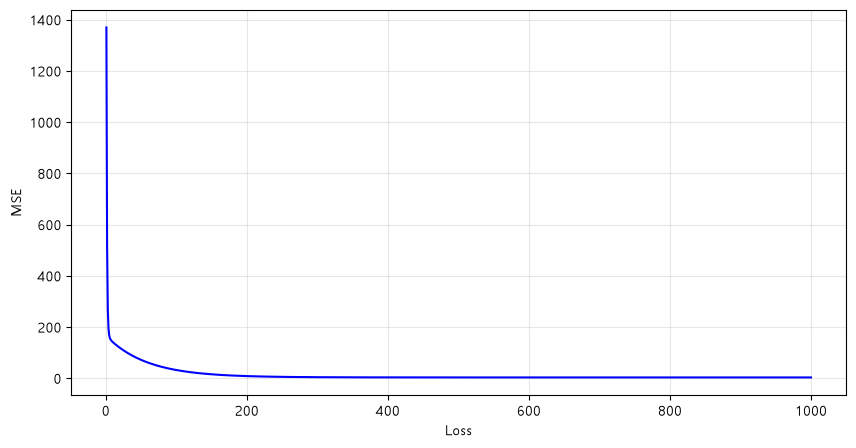

In [14]:
plt.figure(figsize=(10, 5))

# Epoch에 따른 MSE 변화 
plt.plot(
    history_df["epoch"],
    history_df["mse"],
    color="blue",
    label="학습 손실(Tracing Loss)"
)
plt.xlabel("Loss")
plt.ylabel("MSE")
plt.grid(alpha=0.3)
plt.show()

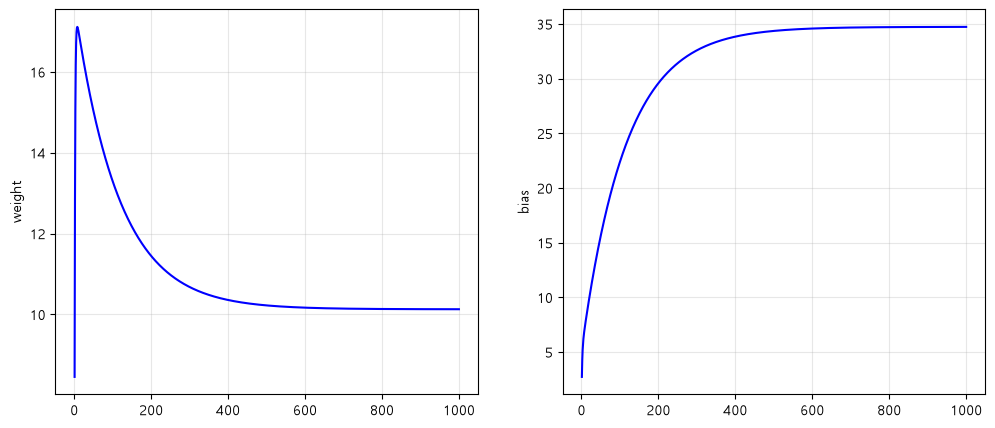

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 기울기 변화 
axes[0].plot(
    history_df["epoch"],
    history_df["weight"],
    color="blue"
)
axes[0].grid(alpha=0.3)
axes[0].set_ylabel("weight")

# 절편 변화 
axes[1].plot(
    history_df["epoch"],
    history_df["bias"],
    color="blue"
)
axes[1].grid(alpha=0.3)
axes[1].set_ylabel("bias")   

plt.show()


In [22]:
# 최종 학습된 기울기, 절편
print(f"기울기(w): {sgd.coef_[0]:.2f}")
print(f"절편(b): {sgd.intercept_[0]:.2f}")

# 6시간 학습한 학생 
new_data = pd.DataFrame({"hours": [6]})

# 경사하강법으로 학습한 모델로 예측
prediction = sgd.predict(new_data)
print(f"예측 성적: {prediction[0]:.2f}점")

기울기(w): 10.13
절편(b): 34.74
예측 성적: 95.52점


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 데이터 생성
df = pd.DataFrame({
    "study_hours":      [1, 2, 3, 4, 5, 2, 3, 5, 4, 1],
    "sleep_hours":      [6, 8, 5, 7, 8, 5, 8, 6, 6, 8],
    "practice_count":   [10, 15, 20, 25, 30, 12, 28, 22, 32, 8],
    "score":            [47, 58, 60, 76, 87, 49, 73, 77, 79, 52]
})

df

,study_hours,sleep_hours,practice_count,score
0,1,6,10,47
1,2,8,15,58
2,3,5,20,60
3,4,7,25,76
4,5,8,30,87
5,2,5,12,49
6,3,8,28,73
7,5,6,22,77
8,4,6,32,79
9,1,8,8,52


<Axes: xlabel='practice_count', ylabel='score'>

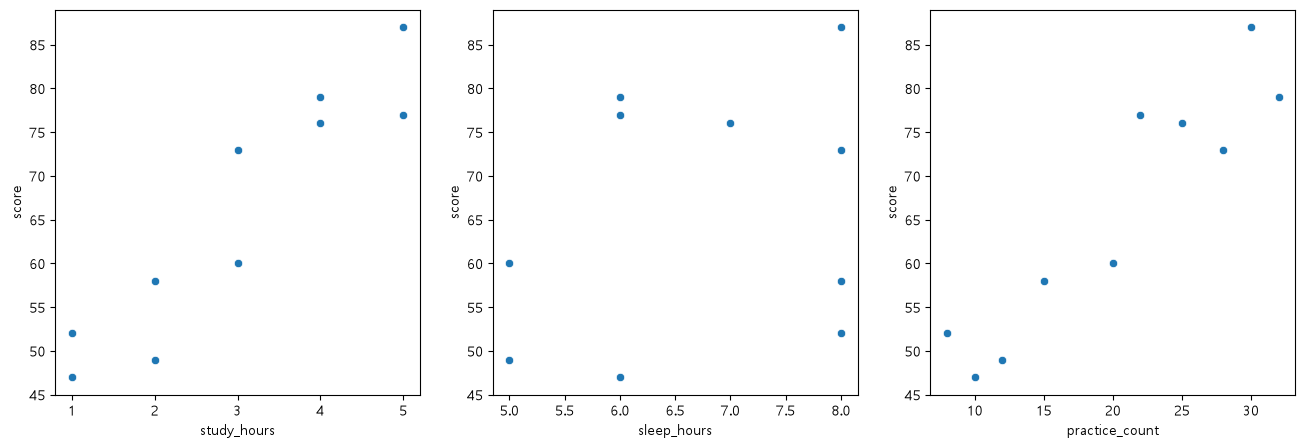

In [25]:
# 1행 3열의 그래프 영역 설정 생성 
fig, axes = plt.subplots(1, 3, figsize=(16,5))

# 공부시간 + 성적
sns.scatterplot(
    data=df,
    x="study_hours",
    y="score",
    ax=axes[0]
)

# 수면시간 + 성적
sns.scatterplot(
    data=df,
    x="sleep_hours",
    y="score",
    ax=axes[1]
)

# 문제풀이 개수 + 성적
sns.scatterplot(
    data=df,
    x="practice_count",
    y="score",
    ax=axes[2]
)

c:\Users\USER\kant\NOV-TIL\nov25\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\USER\kant\NOV-TIL\nov25\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


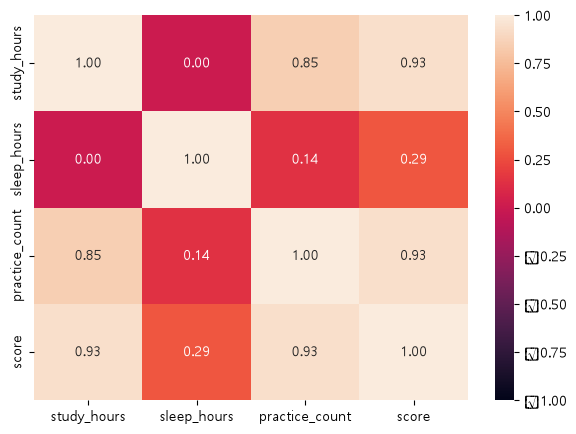

In [28]:
# 상관 계수 확인 
# 모든 컬럼 사이의 상관계수 확인 

corr = df.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr, 
    annot=True, 
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.show()

## 02 수업 내용 뜯어먹기
===

### 01 판다스
>파이썬에서 표(테이블) 형태의 정형 데이터의 시계열 데이터를 조작하고 분석하는 오픈 소스 라이브러리

===
### 02 matplotlib
> 파이썬의 라이브러리 중 하나로 주로 데이터 시각화나 그래프를 그릴때 사용


===
### 03 pyplot
> 파이썬 시각화 라이브러리 Matplotlib에서 MATLAB 스타일의 명령어로 그래프를 쉽게 그릴 수 있게 해주는 모듈 


===
### 04 sklearn(스키킷 학습)
> 머신러닝 라이브러리 중 하나. 데이터 과학 툴 세트. 일관된 인터페이스로 인공지능 ML및 통계 모델링을 간소화 


===
### 05 linear model(선형모델)
> 입력 변수(특성, x)와 가중치(계수, w)의 선형 결합으로 결과를 예측하거나 관계를 설명하는 통계 및 머신러닝 모델 

===
### 06 linear regression(선형회귀)
> 어떠한 독립 변수들과 종속 변수 간의 관계를 에측할때 그 사이 관계를 선형 관계(1차 함수)로 가정하고 모델링하는 지도 학습 알고리즘

===
### 07 plt.rcParams
> matplotlib의 전역설정을 관리하는 딕셔너리 객체. 그래프를 그릴때마다 매번 크기, 폰트, 선 두께 등을 지정하지 않고 기본값을 미리 정해둘때 사용

===
### 08 파이썬 딕셔너리
> 키(key)와 값(value)을 한 쌍으로 저장하는 가변 자료형. 중괄호{}를 사용함. 

===
### 09 파이썬 데이터프레임
> 파이썬에서 행과 열로 구성된 2차원 표(Table) 형태의 데이터 구조 

===
### 10 2차원 독립변수
> 독립변수가 2개인 함수, 회귀분석의 입력(x1, x1) 또는 2차원 공간(R2)에서 서로 선형독립인 두 벡터 

===
### 11 1차원 종족변수
> 통계학, 데이터분석, 머신러닝에서 예측하거나 설명하고자 하는 결과값(y)이 단 하나의 스칼라(단일 값)로 이루어진 변수 

===
### 12 머신러닝 모델
> 데이터를 수집하고 전처리한 뒤 알고리즘으로 학습시켜 새로운 데이터를 예측하거나 분류하도록 만드는 과정

===
### 13 머신러닝 모델 학습
> 훈련 데이터에서 패턴을 찾아 손실 함수를 줄이거나 보상을 높이는 방향으로 모델의 매개변수(가중치, 평향 등)를 최적화하는 과정 

===
### 14 기울기, 절편, 예측
> 기울기: 그래프가 기울어진 정도를 나타냄. x값이 변할때 y값이 변하는 비율 <br>
> 절편: 그래프가 좌표축(x축, y축)과 만나는 지점의 좌표 또는 값<br>
> 예측: 직선의 방정식 y = mx + b에서 기울기(m)와 절편(b)을 구하면 새로운 입력값(x)에 대한 결과값(y)를 예측할 수 있음

===
### 15 figure, axes
> figure는 큰 프레임(스케치북)<br>
> axes는 그 안에 그림을 그릴 수 있는 공간(종이) 

===
### 16 산점도(Scatter plot)
> 두 개의 수치형 변수의 값을 X축과 Y축 좌표 평면 위에 점(x, y)으로 찍어 두 변수 간의 관계와 분포를 나타내는 그래프 

===
### 17 MAE, MSE, R2 score

MAE(평균절대오차):
> 실제값과 예측값 차이의 절댓값 평균 
<br>

MSE(평균제곱오차):
> 실제값과 예측값 차이의 제곱 평균
<br>

R2 score(결정계수): 
> 상관계수를 제곱한 값으로 보면 된다 하지만 결정 계수는 상관계수와 달리 변수간 영향을 주는 정도 또는 인과 관계의 정도를 정량화해서 나타낸 수치이다 따라서 결정계수는 상관분석이 아닌 회귀분석에서 사용하는 수치

===
### 18 경사 하강법(Gradient Descent)
> 함수의 최솟값을 찾기 위해 현재 위치에서 기울기(미분값)를 구하고 그 반대 방향으로 조금씩 이동하는 과정을 반복하는 최적화 알고리즘

===
### 19 손실함수(Loss Function)
> 머신러닝, 딥러닝 모델이 예측한 값과 실제 정답 사이의 차이를 숫자로 계산하는 함수 

===
### 20 SGDRegresspr
> 사이킷런에서 확률적 경사 하강법으로 선형 회귀 모델을 학습시키는 클래스 

===
### 21 가중치, 편향, 예측값

Weight(가중치)
> 입력 변수(x)가 예측값에 미치는 영향력(기울기)을 조절하는 매개변수. w의 절댓값이 클수록 해당 입력 특성이 결과에 큰 영향
<br>

Bias(편향)
> 입력값이 0일때 기본 출력값(y절편)을 결정하며 모델이 데이터에 더 유연하게 맞춰지도록 그래프 전체를 위아래로 이동시키는 역할
<br>

y hat(예측값)
> 입력 데이터(x)를 바탕으로 모델이 계산해 낸 결과값. 가장 기본적인 선형 회귀 모델에서는 다음과 같은 일차방정식 형태로 계산 

### 01 개념1
===

### 01 개념1
===

### 01 개념1
===

## 03 오늘 만난 에러
===

### 01 AttributeError: module 'matplotlib.pyplot' has no attribute 'Subplots'
===>
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
> subplots인데 s를 대문자S로 적어서 오류남. 

### 01 에러1
===

### 01 에러1
===

### 01 에러1
===

### 01 에러1
===

## 04 Today's Brain Status
===

## 05 수업후기
===